#  Simulating Planetary Orbits

# Introduction

Planets orbiting the Sun in our solar system can be modelled using numerical methods. These methods are approximate techniques used to solve mathematical problems that are difficult or impossible to solve analytically [1]. One such method is Euler's method [2], which when combined with Newtonian gravity, can be used to simulate orbital trajectories. 
The gravitational force can be found using: $$F = \frac{-GMm}{r^2}$$
$$\tag{1}$$

where F is gravitational force, ($kgms^{-2}$), G is the gravitational constant ($m{^3} kg^{-1} s^{-2}$), M and m are the bodies on which the force acts ($kg$) and r is the separation between the bodies ($m$).

Euler’s method updates the positions and velocities over a small time step, dt, using:
$$ x_1 = x_0 + v_{x0}dt $$ $$\tag{2.1}$$
$$v_{x1}=v_{x0}+a_{x0}dt$$ $$\tag{2.2}$$
$$a_{x1}= GM/x_{1}^2$$ $$\tag{2.3}$$
$$[3]$$

where $x_1$ is the separation at the next step ($m$), $v_{x1}$ and $a_{x1}$ are the velocity ($ms^{-1}$) and acceleration ($ms^{-2}$) respectively at this step, and dt is a small increment of time ($s$). In the case of orbital motion, the acceleration is determined by the gravitational force due to the Sun, in 2D:
$$\vec{a} = -\frac{GM}{r^2}\,\hat{r}$$
$$\tag{3}$$


Euler's method then approximates the successive positions and time-derivatives after a small increment of time [3]. 

# A Single Planet

In [1]:
import numpy as np
from phas0007anim_v2 import animate_trajectory_2d, animate_trajectories_2d
import matplotlib.pyplot as plt
import tabulate as tabulate

In [2]:
G       = 6.6743e-11 # gravitational constant [m^3 kg^-1 s^-2]
YEAR    = 3.154e7    # one year in seconds [s]
M_SOLAR = 1.989e30   # solar mass [kg]
AU      = 1.496e11   # one astronomical unit (mean orbital radius of Earth) [m]
mE      = 5.9722e24  # mass of earth [kg]

In [3]:
def force(pos1, pos2, m1, m2):
    """
    Calculate the gravitational force exerted by object 1 on object 2.
    
    Input:
        pos1: position vector of first object  (NumPy array)
        pos2: position vector of second object (NumPy array)
        m1:   mass of first object
        m2:   mass of second object

    Depends on:
        G  (global variable):    gravitational constant [m^3 kg^-1 s^-2]

    Return:
        force on object 2 [N] (NumPy array)
    """
    
    r_vec = pos2 - pos1 # finding displacement vector from 1 to 2
    r_mag = np.linalg.norm(r_vec) # distance between objects
    r_hat = r_vec/ r_mag # unit vector in direction or r_vec
    F_mag = -G * m1 * m2 / r_mag**2 # mag of grav force
    F = F_mag * r_hat # grav force as vector

    return F

In [4]:
def move_planet(position, velocity, m_star, dt):
    """
    Calculate motion of planet in the gravitational field of a star with given mass
    at the originin two dimensions, using Euler's method.
    
    Input:
      - position: position vector of planet at start of time step (NumPy array: x, y)
      - velocity: velocity vector of planet at start of time step (NumPy array: vx, vy)
      - m_star:   mass of star
      - dt:       time step
      
    Output: (position_new, velocity_new)
      - position_new: position vector of planet at end of time step (NumPy array: x, y)
      - velocity_new: velocity vector of planet at end of time step (NumPy array: vx, vy)
      
    Depends on:
      - force = function to calculate the gravitational force between two objects
    """
    
    m_planet = 1.0 
    pos_star = np.array([0.0, 0.0]) # sun position fixed

    F = force(pos_star, position, m_star, m_planet)
    a = F / m_planet

    # Euler method [2]
    velocity_new = velocity + a * dt
    position_new = position + velocity * dt

    return position_new, velocity_new

In [5]:
# code in cell adapted for orbital motion, from unit 9 task
def trajectory(position, velocity, m_star, dt, t_max):
    """
    Calculate trajectory of planet from given starting position in two dimensions, using Euler's method.
    
    Input:
      - position: position vector of planet at start of simulation [m] (NumPy array: x, y)
      - velocity: velocity vector of planet at start of simulation [m] (NumPy array: vx, vy)
      - m_star:   mass of star [kg]
      - dt:       time step    [s]
      - t_max:    duration of calculated motion [s]

    Returns:
        Trajectory as a 2 x N array containing x and y coordinates at each instant.
    """
    # current time
    t = 0.0
    x, y = position  # unpack position vector into components
    x_arr, y_arr = [x], [y] # makes components into arrays ie x=2, x_arr=[2]

    # step forward until reaching t_max
    while t < t_max:
        position, velocity = move_planet(position, velocity, m_star, dt)
        x, y = position
        x_arr.append(x) # adds x to end of list
        y_arr.append(y) # adds y to end of list

        # add to time AFTER step
        t += dt
        
    traj = np.vstack((x_arr, y_arr))
    return traj

In [6]:
def plot_trajectory(x, y, fmt='--', label="trajectory"):
    """Plot trajectory with equal aspect ratio, using existing figure.

    Arguments:
        x, y:  arrays of x- and y-coordinates
        label: (optional) label for use in legend
        fmt:   (optional) format to use for plotting, e.g. ':' for dotted line
    """
    plt.plot(x,y,fmt,label=label)
    plt.gca().set_aspect('equal') # same scale horizontally and vertically
    plt.xlabel('x [m]')
    plt.ylabel('y [m]')

Below, the equation for circular motion is used to find Earth's orbital velocity: $$v = \sqrt{\frac{GM}{r}}$$
$$\tag{4}$$

This is then used in conjunction with Euler's method, (2), to obtain velocity and position vectors to construct Earth's trajectory, step by step. 

In [7]:
# calculate orbital speed of Earth [m/s] assuming circular orbit
v_earth = np.sqrt(G*M_SOLAR/AU)
print(f'orbital speed of earth = {v_earth:.2e} ms^-1') 

# initial conditions of planet
pos_earth = np.array([AU, 0])       # position (x,y) [m]
vel_earth = np.array([0,v_earth])   # velocity (vx,vy) [m/s]

orbital speed of earth = 2.98e+04 ms^-1


Here, Earth's trajectory around the sun will be plotted after:
- a) one year
- b) five years 

## a) 1 Year

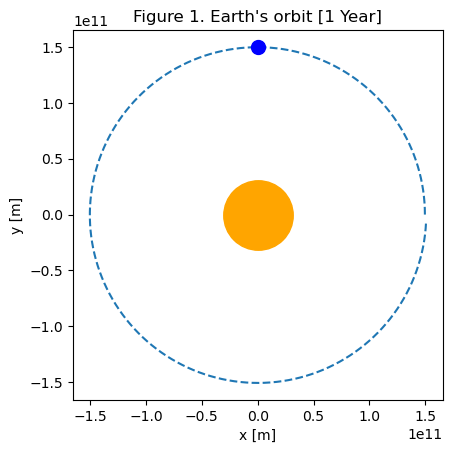

In [8]:
# calculate trajectory
dt = YEAR/10000                # time step for Euler's method [s]
traj_earth = trajectory(pos_earth,vel_earth,M_SOLAR,dt,YEAR)

# plot trajectory
plt.figure()
plt.title("Figure 1. Earth's orbit [1 Year]")
x_earth, y_earth = traj_earth
plot_trajectory(x_earth, y_earth)
plt.plot(0,0, color='orange', marker='o', markersize='50')
plt.plot(0,1.5e11, color='blue', marker='o', markersize='10');

## b) 5 Years

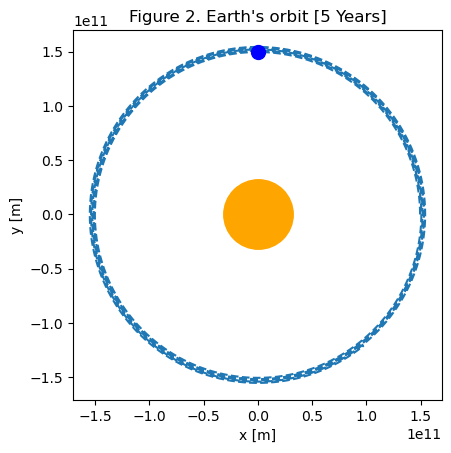

In [9]:
# calculate trajectory
dt = YEAR/10000                # time step for Euler's method [s]
traj_earth = trajectory(pos_earth,vel_earth,M_SOLAR,dt,5*YEAR)

# plot trajectory
plt.figure()
plt.title("Figure 2. Earth's orbit [5 Years]")
x_earth, y_earth = traj_earth
plot_trajectory(x_earth, y_earth)
plt.plot(0,0, color='orange', marker='o', markersize='50')
plt.plot(0,1.5e11, color='blue', marker='o', markersize='10');

Already, small slips can be seen in the simulated trajectories.
In part a), the orbit appears to contain a gap. This is because the variant of Euler's method being used, Explicit Euler, updates the position using older velocities. This causes numerical errors which increase with each step, quickly becoming very large [4].
In part (b), the orbital radius increases over time, producing a visibly thickened trajectory. This behaviour is physically incorrect and is because Euler's method does not conserve the total mechanical energy of the system. As a result, numerical errors compound leading to an increase in kinetic and potential energy. This causes the Earth to drift away from the Sun. 

# A Single Planet - Varying the time step

Alongside varying the number of orbits simulated, the accuracy of the numerical trajectory can be investigated by varying the time step used in the calculation.

For a given time step, the simulations can be asessed for accuracy by calculating the total mechanical energies of the orbit systems. This energy can be calculated using: $$E_{(t)} = \frac{1}{2}mv^2 - \frac{GMm}{r}$$ 
$$\tag{5}$$

To quantify the simulation's accuracy for different time steps, the conservation of total mechanical energy can be assessed by calculating the relative energy change: $$\frac{E-E_0}{|E_0|}$$
$$\tag{6}$$
Where $E$ and $E_0$ are the final and initial values of mechanical energy, (J). 

### a) very large time step

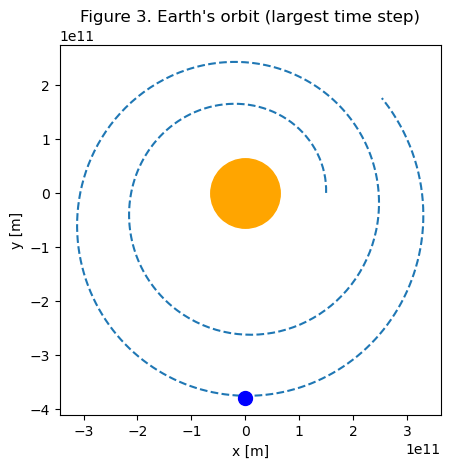

In [10]:
# calculate trajectory
dt = YEAR/(10000*0.01)                # time step for Euler's method [s]
traj_earth = trajectory(pos_earth,vel_earth,M_SOLAR,dt,5*YEAR)

# plot trajectory
plt.figure()
plt.title("Figure 3. Earth's orbit (largest time step)")
x_earth, y_earth = traj_earth
plot_trajectory(x_earth, y_earth)
plt.plot(0,0, color='orange', marker='o', markersize='50')
plt.plot(0,-3.8e11, color='blue', marker='o', markersize='10');


In [11]:
# unpacking
x = np.array(x_earth)
y = np.array(y_earth)

vx = np.gradient(x, dt) # vx is d/dt of x
vy = np.gradient(y, dt) # vy is d/dt of y

r = np.sqrt(x**2 + y**2) # calulcates distance of every list of x, y position
v2 = vx**2 + vy**2

# Energy conservation
E = 0.5 * mE * v2 - G * M_SOLAR * mE / r
E0 = E[0]

rel_E_change = (E - E0)/ abs(E0)
print(f'relative energy change for the largest time step = {rel_E_change[-1]:.2f}')

relative energy change for the largest time step = 0.57


### b) large time step

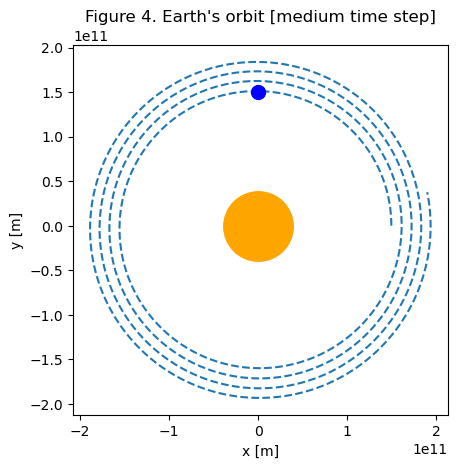

In [12]:
# calculate trajectory
dt = YEAR/(10000*0.1)                # time step for Euler's method [s]
traj_earth = trajectory(pos_earth,vel_earth,M_SOLAR,dt,5*YEAR)

# plot trajectory
plt.figure()
plt.title("Figure 4. Earth's orbit [medium time step]")
x2_earth, y2_earth = traj_earth
plot_trajectory(x2_earth, y2_earth)
plt.plot(0,0, color='orange', marker='o', markersize='50')
plt.plot(0,1.5e11, color='blue', marker='o', markersize='10');

In [13]:
# unpacking
x = np.array(x2_earth)
y = np.array(y2_earth)

vx = np.gradient(x, dt) # vx is d/dt of x
vy = np.gradient(y, dt) # vy is d/dt of y

r = np.sqrt(x**2 + y**2) # calulcates distance of every list of x, y position
v2 = vx**2 + vy**2

# energy conservation
E = 0.5 * mE * v2 - G * M_SOLAR * mE / r
E0 = E[0]

rel_E_change = (E - E0)/ abs(E0)
print(f'relative energy change for a medium time step = {rel_E_change[-1]:.2f}')

relative energy change for a medium time step = 0.23


### c) small time step

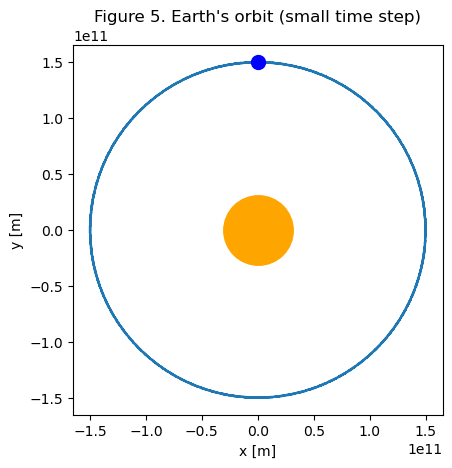

In [14]:
# calculate trajectory
dt = YEAR/(10000*10)                # time step for Euler's method [s]
traj_earth = trajectory(pos_earth,vel_earth,M_SOLAR,dt,5*YEAR)

# plot trajectory
plt.figure()
plt.title("Figure 5. Earth's orbit (small time step)")
x3_earth, y3_earth = traj_earth
plot_trajectory(x3_earth, y3_earth)
plt.plot(0,0, color='orange', marker='o', markersize='50')
plt.plot(0,1.5e11, color='blue', marker='o', markersize='10');

In [15]:
# unpacking
x = np.array(x3_earth)
y = np.array(y3_earth)

vx = np.gradient(x, dt) # vx is d/dt of x
vy = np.gradient(y, dt) # vy is d/dt of y

r = np.sqrt(x**2 + y**2) # calulcates distance of every list of x, y position
v2 = vx**2 + vy**2

# energy conservation
E = 0.5 * mE * v2 - G * M_SOLAR * mE / r
E0 = E[0]

rel_E_change = (E - E0)/ abs(E0)
print(f'relative energy change for small time step = {rel_E_change[-1]:.4f}')

relative energy change for small time step = 0.0039


In [16]:
a = [
    [ '3*10^{7}', '0.57'],
    [ '3*10^{4}', '0.23' ],
    [ '3*10^{2}','0.0039']
]
 
headers = ['time step/ dt [s]', 'relative energy change']
print(tabulate.tabulate(a,headers,tablefmt="grid"))

+---------------------+--------------------------+
| time step/ dt [s]   |   relative energy change |
+=====================+==========================+
| 3*10^{7}            |                   0.57   |
+---------------------+--------------------------+
| 3*10^{4}            |                   0.23   |
+---------------------+--------------------------+
| 3*10^{2}            |                   0.0039 |
+---------------------+--------------------------+


$Table - 1$

From Table 1, it can be seen that as the time step is decreased, the relative error in total mechanical energy becomes smaller. This indicates that the simulated orbits become more accurate as the time step is reduced.

In closed systems, the energy should be conserved, meaning that the relative energy change should be zero. However, the discrepancies seen in Table 1 arise from the use of the explicit Euler method which does not conserve energy. This method relies on finding the position and velocity vectors based on the old velocity and hence numerical errors accumulate over time [4]. This leads to an increase in the planet's total energy, which is reflected by the positive relative energy changes and the outward spirals in trajectories.

As the time step is decreased, the relative energy change becomes smaller. Hence, it is possible to find a reasonable time step by requiring the energy deviation to be close to zero. In this investigation, a relative energy change of less than 1% was deemed to produce physically reasonable orbits. 

# A Single Planet - Varying the initial speed

Here, the initial speeds will be varied between 0.5x and 4x Earth's orbital speed. The effects of these changes can then be seen on the simulated trajectories. 

## a) Intermediate speeds between actual and escape velocity

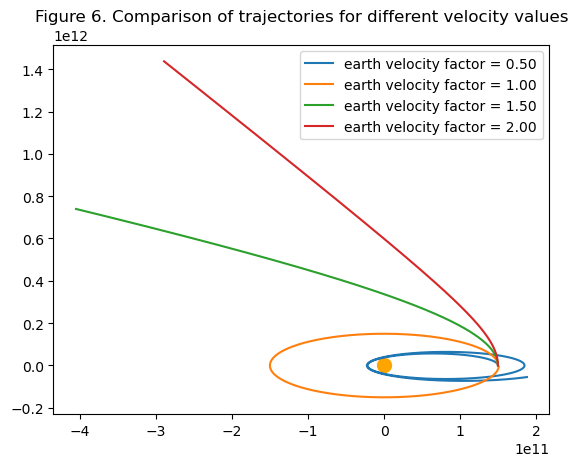

In [17]:
# calculate trajectory
dt = YEAR/(10000)                # time step for Euler's method [s]

# plot trajectory
plt.figure()
plt.plot(0,0, color='orange', marker='o', markersize='10')
for speed_factor in np.linspace(0.5,2,4):
    vel = np.array([0, speed_factor* v_earth])
    x, y = trajectory(pos_earth,vel,M_SOLAR,dt,YEAR)
    plt.plot(x, y, label=f"earth velocity factor = {speed_factor:.2f}")
plt.legend()
plt.title("Figure 6. Comparison of trajectories for different velocity values");

# code adapted from unit 9 work

## b) At escape velocity

escape velocity of Earth = 4.2e+04 ms^-1


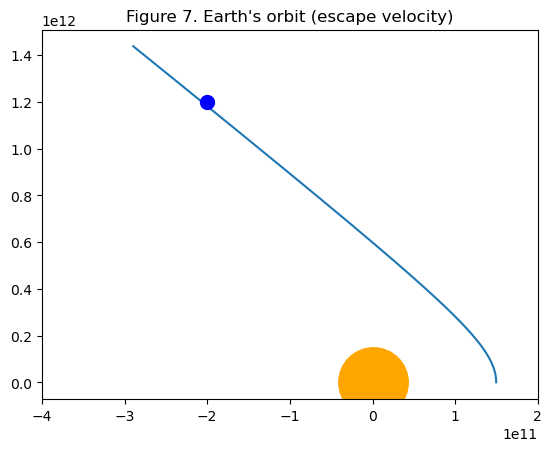

In [18]:
# calculate trajectory
dt = YEAR/(10000)                # time step for Euler's method [s]
vel_e_esc = np.sqrt(2*G*M_SOLAR/AU)
print(f'escape velocity of Earth = {vel_e_esc:.1e} ms^-1')
traj_earth = trajectory(pos_earth,vel_earth,M_SOLAR,dt,YEAR)

vel_2 = np.array([0, vel_e_esc])
x_esc, y_esc = trajectory(pos_earth,vel,M_SOLAR,dt,YEAR)

# plot trajectory
plt.figure()
plt.title("Figure 7. Earth's orbit (escape velocity)")
plt.plot(x, y, label=f"velocity of earth = {vel_e_esc}");
plt.plot(0,0, color='orange', marker='o', markersize='50')
plt.plot(-2e11,1.2e12, color='blue', marker='o', markersize='10')
plt.xlim(-4e11, 2e11)
plt.rcParams['figure.figsize'] = 2, 2

In [19]:
x = np.array(x_esc)
y = np.array(y_esc)

vx = np.gradient(x, dt) # vx is d/dt of x
vy = np.gradient(y, dt) # vy is d/dt of y

r = np.sqrt(x**2 + y**2) # calulcates distance of every list of x, y position
v2 = vx**2 + vy**2

# energy conservation
E = 0.5 * mE * v2 - G * M_SOLAR * mE / r
E0 = E[0]

rel_E_change = (E - E0)/ abs(E0)
print(f'Relative energy change at escape velocity = {rel_E_change[-1]:.4f}') 

Relative energy change at escape velocity = 0.0003


For inital velocities below Earth's orbital velocity, the resulting trajectory becomes very eliptical, with a high eccentricity. This is expected as reducing the orbital speed below the escape velocity at that point results in an eliptical orbit as opposed to circular or hyperbolic orbits [5].

For sufficiently large initial velocities, the trajectory becomes unbound and the Earth escapes the Sun’s gravitational influence. This occurs when the initial speed exceeds the escape velocity, at which point the orbit transitions from elliptical to parabolic or hyperbolic [5].

The accuracy of the numerical calculations seem to be quite insensitive to the initial speed. This could be as unbound trajectories do not repeatedly revisit the same space and hence small numerical errors are not reinforced in the same way as for circular orbits. This led to a comparatively small relative energy change of 0.03%

# Two Interacting Planets

Euler’s method can also be used to calculate and plot the orbits of two bodies orbiting a larger, fixed body. In this restricted three body problem, [6],  Earth and Venus are simulated to revolve around the Sun over a period of five years, taking into account the gravitational effect of each planet on another. 

For this, the force on each planet can be written as:
$$F_{earth} = F_{star->earth} + F_{venus->earth}$$ $$\tag{7.1}$$
$$F_{venus} = F_{star->venus} + F_{earth->venus}$$ $$\tag{7.2}$$

where the gravitational forces F are given by (1). 

Here, two concepts are investigated:
- a) Venus and Earth orbiting the sun
- b) Effect of varying the mass of Venus on Earth's orbit

## Venus and Earth orbitting the sun

In [20]:
# library of constants, global variables
r_venus = 0.72*AU
posV = np.array([r_venus, 0])
velV = np.array([0, np.sqrt(G*M_SOLAR/r_venus)])
posE = np.array([AU, 0])
velE = np.array([0, v_earth])
mE = 5.9722e24
mV = 4.867e24
m_star = M_SOLAR
t_max = YEAR
dt = YEAR/1000

In [21]:
def move_planets(posE, velE, mE, posV, velV, mV, m_star, dt, pos_star):
    """
    Advance two planets by one explicit Euler step under gravity from a fixed star
    at the origin and their mutual gravity.

    Inputs:
      - pos1, pos2: positions of planet 1 and 2 at start of step (np.array([x, y]))
      - vel1, vel2: velocities of planet 1 and 2 at start of step (np.array([vx, vy]))
      - m1, m2:     masses of planet 1 and 2 [kg]
      - m_star:     mass of star [kg]
      - dt:         time step [s]
      - pos_star:   position of star (default [0,0])

    Depends on:
      - force = function to calculate the gravitational force between two objects
      
    Returns:
      - pos1_new, vel1_new, pos2_new, vel2_new
    """
    
    # forces due to star (3)
    FE_star = force(pos_star, posE, m_star, mE)  # on earth due to star
    FV_star = force(pos_star, posV, m_star, mV)  # on venus due to star

    # forces due to planets (3)
    FE_V = force(posV, posE, mV, mE)             # on earth due to venus
    FV_E = force(posE, posV, mE, mV)             # on venus due to earth

    # accelerations
    aE = (FE_star + FE_V) / mE
    aV = (FV_star + FV_E) / mV

    # explicit euler updates 
    velE_new = velE + aE * dt
    velV_new = velV + aV * dt

    posE_new = posE + velE * dt
    posV_new = posV + velV * dt

    return posE_new, velE_new, posV_new, velV_new

In [22]:
def trajectories(posE, velE, mE, posV, velV, mV, m_star, dt, t_max, pos_star):
    """
    Calculate trajectories of planets from given starting position in two dimensions, using Euler's method.

    Inputs:
      - posE, posV: initial positions [m] (np.array([x, y]))
      - velE, velV: initial velocities [m/s] (np.array([vx, vy]))
      - mE, mV:     planet masses [kg]
      - m_star:     star mass [kg]
      - dt:         time step [s]
      - t_max:      total duration [s]
      - pos_star:   star position (default [0,0])

    Returns:
      - trajE:  2 x N array (x,y for Earth)
      - trajV:  2 x N array (x,y for Venus)
      - vtrajE: 2 x N array (vx,vy for Earth)
      - vtrajV: 2 x N array (vx,vy for Venus)
    """
    # current state
    xE, yE = posE
    vx_E, vy_E = velE
    xV, yV = posV
    vx_V, vy_V = velV

    # storage
    xE_arr, yE_arr = [xE], [yE]
    vx_E_arr, vy_E_arr = [vx_E], [vy_E]

    xV_arr, yV_arr = [xV], [yV]
    vx_V_arr, vy_V_arr = [vx_V], [vy_V]

    t = 0.0
    while t < t_max:
        pE = np.array([xE, yE])
        vE = np.array([vx_E, vy_E])
        pV = np.array([xV, yV])
        vV = np.array([vx_V, vy_V])

        pE, vE, pV, vV = move_planets(pE, vE, mE, pV, vV, mV, m_star, dt, pos_star)

        # unpack
        xE, yE= pE
        vx_E, vy_E = vE
        xV, yV = pV
        vx_V, vy_V = vV

        # record
        xE_arr.append(xE); yE_arr.append(yE)
        vx_E_arr.append(vx_E); vy_E_arr.append(vy_E)

        xV_arr.append(xV); yV_arr.append(yV)
        vx_V_arr.append(vx_V); vy_V_arr.append(vy_V)

        t += dt

    trajE  = np.vstack((xE_arr,  yE_arr))
    trajV  = np.vstack((xV_arr,  yV_arr))
    vtrajE = np.vstack((vx_E_arr, vy_E_arr))
    vtrajV = np.vstack((vx_V_arr, vy_V_arr))

    return trajE, trajV, vtrajE, vtrajV

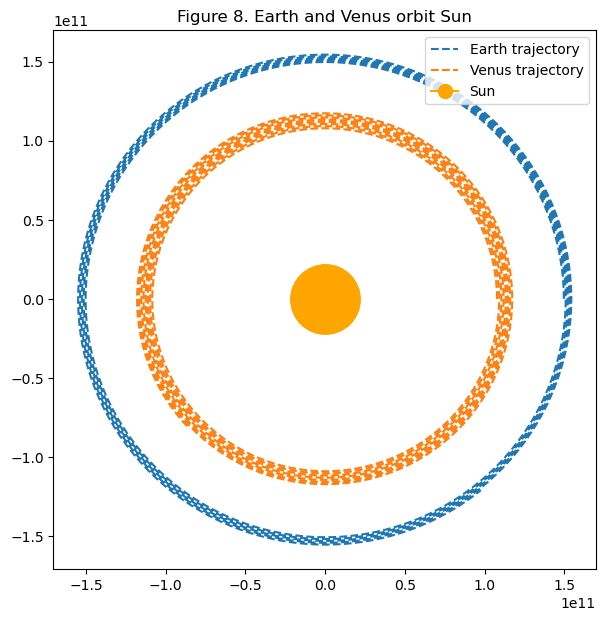

In [23]:
dt= YEAR/10000
trajE, trajV, vtrajE, vtrajV = trajectories(posE, velE, mE, posV, velV, mV, m_star, dt, 5*YEAR, np.array([0,0]))
xE, yE = trajE
xV, yV = trajV

# plotting
plt.figure(figsize=(7, 7))
plt.plot(xE, yE, '--', label="Earth trajectory")
plt.plot(xV, yV, '--', label="Venus trajectory")
plt.plot(0,0, markersize='50', marker='o', color='orange')
plt.plot(0,0, markersize='10', marker='o', color='orange', label='Sun')
plt.legend(loc='upper right');
plt.title("Figure 8. Earth and Venus orbit Sun");

# Two Interacting Planets - Varying the mass of Venus

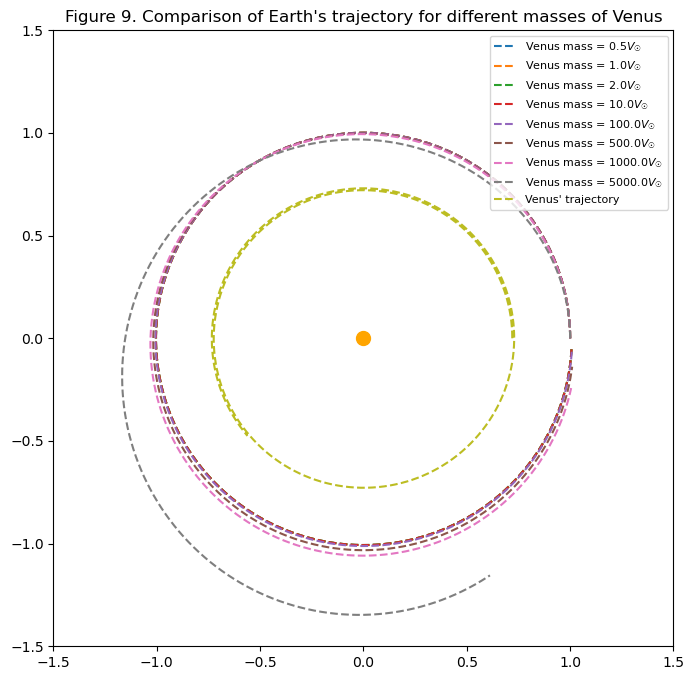

In [24]:
# calculate trajectory
dt = YEAR/(10000)                # time step for Euler's method [s]

# plot trajectory
plt.figure(figsize=(8,8))
plt.plot(0,0, color='orange', marker='o', markersize='10')
Vm_factors = np.array([0.5,1,2,10,100,500,1000,5000])
for mV_SF in Vm_factors:
    var_mV = float(mV_SF * mV)
    trajE, trajV, vtrajE, vtrajV = trajectories(posE, velE, mE, posV, velV, var_mV, m_star, dt, YEAR, np.array([0,0]))
    xE, yE = trajE
    xV, yV = trajV
    plt.plot(xE/AU, yE/AU, '--', label=f"Venus mass = {mV_SF}$V_☉$")
plt.plot(xV/AU, yV/AU, '--', label="Venus' trajectory")
plt.legend(loc='upper right', fontsize=8, markerscale=0.5)
plt.title("Figure 9. Comparison of Earth's trajectory for different masses of Venus");
plt.xlim(-1.5, 1.5);
plt.ylim(-1.5, 1.5);
# code adapted from unit 9 work

There was no noticeable difference in the orbit of Earth when Venus' mass was varied, until the mass became sizeably large. This is because Venus' mass did not affect Earth's orbit around a much larger body. This change in trajectory is only noticeable when $V_☉$ is five hundred or a thousand times larger. Then, the gaps in orbits became much more visible when compared to smaller multiples of Venus' mass.

This also explains why in Figure 8, adding venus does not visibly change the trajectory at all. The force exerted by Venus on Earth is negligible compared to the force exerted by the Sun on Earth. 

$$F_{venus->earth} = 1.3× 10^{18} $$ $$\tag{8.1}$$
$$F_{sun->earth} = 3.5 × 10^{22} $$ $$\tag{8.2}$$
$$ \frac{ F_{venus->earth}} {F_{sun->earth}} ≈ 10^{-5}$$ $$\tag{8.3}$$

Hence the gravitational force by Venus on Earth is roughly $10^{5}$ times smaller than the force of the Sun on Earth.

## Animation when $V_☉$ × 5500

In [25]:
fps = 5
t_max_anim = 0.2*YEAR
trajE, trajV, vtrajE, vtrajV = trajectories(posE, velE, mE, posV, velV, mV*5500, m_star, dt, 1*YEAR, np.array([0,0]))
factor = 20  # take every 20th point
trajE_ds = trajE[:, ::factor]  # downsample x and y
trajV_ds = trajV[:, ::factor]  

animate_trajectories_2d([trajE_ds, trajV_ds], fps, t_max_anim)

It can thus be seen that the Earth strays further from the Sun as the animation progresses.

# Further investigation

Whilst using Euler's method is easy to implement, it is not the most efficient and does not conserve energy as well as other methods. Another method which can be used to calculate and plot trajectories is the Midpoint method. This is a second-order Runge-Kutta (RK2) method, that provides significantly better accuracy than the Euler method, by evaluating the derivative at the midpoint of each time step [3]. 

## Midpoint method

Initially, midpoint estimates can be calculated using:
 $$x_{0.5} = x_0 + v_{x0}dt / 2 $$ $$\tag{9.1}$$
 $$v_{x0.5} = v_{x0} + a_{x0}dt / 2$$ $$\tag{9.2}$$
 $$a_{x0.5} = Gm / x_{0.5}^2$$ $$\tag{9.3}$$

 These are then used to find the successive steps:
 $$x_{1} = x_0 + v_{x0.5}dt $$ $$\tag{9.4}$$
 $$v_{x1} = v_{x0} + a_{x0.5}dt $$ $$\tag{9.5}$$
 $$a_{x1} = Gm / x_{1}^2$$ $$\tag{9.6}$$
$$[3]$$

In [26]:
# Constants
G = 6.67430e-11  # m^3 kg^-1 s^-2
AU = 1.496e11    # meters

# code in cell adapted from [7], translated from R to Python, calulates relative energy change instead of energy ratio
def midpoint_two_body(T, N, m_a, m_b,
                      r_ax0, r_ay0, r_bx0, r_by0,
                      v_ax0, v_ay0):
    """
    Earth orbiting fixed Sun using Midpoint Method.
    Returns Earth positions, Sun position, and relative energy change.
    """

    dt = T / N

    # earth initial conditions
    r_a = np.array([r_ax0, r_ay0])
    v_a = np.array([v_ax0, v_ay0])

    # sun fixed at origin
    r_b = np.array([r_bx0, r_by0])

    x_a, y_a = [r_ax0], [r_ay0]
    x_b, y_b = [r_bx0], [r_by0]

    # initial energy
    KE_0 = 0.5 * m_a * np.sum(v_a**2)
    r_ab0 = np.linalg.norm(r_a - r_b)
    U_0 = -G * m_a * m_b / r_ab0
    E_0 = KE_0 + U_0

    for i in range(N):
        # vector from Earth to Sun
        r_ab = r_a - r_b
        mag_r_ab = np.linalg.norm(r_ab)

        # acceleration at current step
        a_a = -G * m_b * r_ab / mag_r_ab**3

        # midpoint estimates
        r_amid = r_a + 0.5 * dt * v_a
        a_mid = -G * m_b * (r_amid - r_b) / np.linalg.norm(r_amid - r_b)**3
        v_amid = v_a + 0.5 * dt * a_a

        r_a = r_a + dt * v_amid
        v_a = v_a + dt * a_mid

        x_a.append(r_a[0])
        y_a.append(r_a[1])

    # final energy
    KE_N = 0.5 * m_a * np.sum(v_a**2)
    r_abN = np.linalg.norm(r_a - r_b)
    U_N = -G * m_a * m_b / r_abN
    E_N = KE_N + U_N
    energy_change = (E_N - E_0)/abs(E_0)

    return x_a, y_a, x_b, y_b, energy_change


<Figure size 200x200 with 0 Axes>

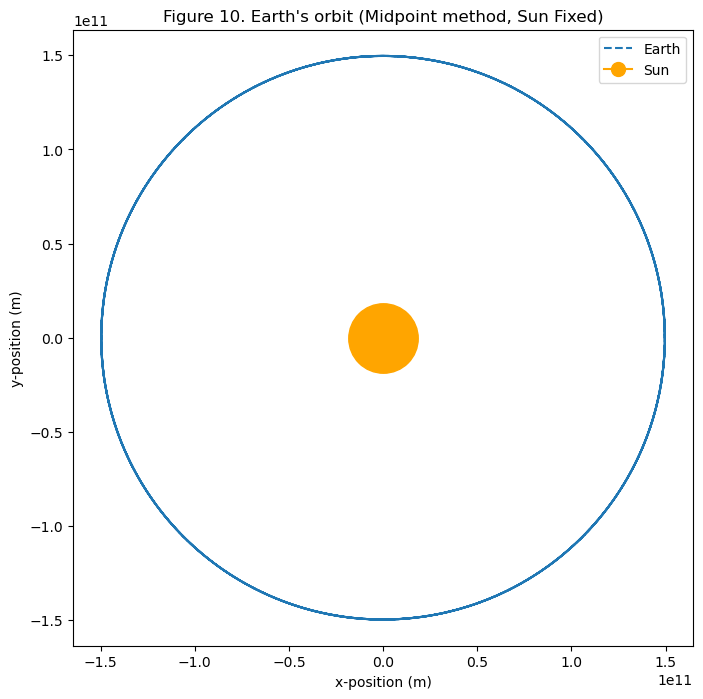

Relative energy change: 0.00012
time step (dt): 3.2e+04 s


In [27]:
# code in cell adapted from [7], translated from R to Python
N = 1000

x_a, y_a, x_b, y_b, energy_change = midpoint_two_body(
    5*YEAR, N,
    m_a=mE, m_b=M_SOLAR,
    r_ax0=AU, r_ay0=0,
    r_bx0=0, r_by0=0,
    v_ax0=0, v_ay0=v_earth
)

plt.figure(figsize=(8,8));
plt.plot(x_a, y_a, '--', label="Earth")
plt.plot(0,0, markersize='50', marker='o', color='orange')
plt.plot(0,0, markersize='10', marker='o', color='orange', label='Sun') # Sun as a star
plt.xlabel("x-position (m)")
plt.ylabel("y-position (m)")
plt.title("Figure 10. Earth's orbit (Midpoint method, Sun Fixed)")
plt.axis("equal")
plt.legend()
plt.show()

print(f"Relative energy change: {energy_change:.5f}")
print(f"time step (dt): {YEAR/N:.1e} s")

From Figure 10, despite the time step being quite large and five orbits being plotted, the relative energy change is considerably smaller than the same orbit simulated using the Euler method. 

After comparing both the plots for Euler's method and the Midpoint method when **dt = $3 × 10^4$** and **T = 5** years, the relative energy change from Euler's method gives **0.23** wheras the Midpoint method gives **0.00012**. This means the Midpoint method is almost **2000x** more accurate for energy conservation.

However, both methods still cause a small outward drift and hence the relative energy change is positive due to a gain in overall energy in both systems. Other methods include evaluating derivatives at further intermediate points. This results in methods such as the fourth-order Runge-Kutta (RK4) method, which evaluates derivatives at four intermediate points. Despite requiring further calculations, the extra work from higher gradient evaluations is typically offset by the increased accuracy [4]. 

# Conclusion

In this notebook, numerical methods were used to calculate and plot the trajectories of celestial objects orbiting the Sun. The behaviour of these trajectories was investigated by changing variables such as the time period, time step, velocity and mass of orbiting bodies. Eventually, a restricted three body problem [6], was investigated with both Venus and Earth orbiting a fixed Sun. Lastly, the energy efficiency of two numerical methods (Euler and Midpoint) were tested and compared. 

Using Euler's method, it was found that decreasing the time step improved the accuracy of the simulated orbits, producing circular trajectories with reduced energy drift. Initial velocities below Earth's orbital velocity led to eliptical orbits, whilst larger initial velocities led to unbound hyperbolic trajectories in which the planet left the solar system entirely when the escape velocity was exceeded. The numerical accuracy of these simulations was relatively insensitive to changes to the initial velocity, in particular when investigating the escape velocity. In fact, energy was conserved better for hyperbolic and unbound orbits rather than circular ones. In the two-planet simulations, Venus had a negligble effect on Earth's orbit at it's true mass, only exhibiting a noticeable effect when five hundred or a thousand times more massive. 

Finally, the Midpoint method outperformed Euler's method in terms of energy conservation. For the same time step, the relative energy error produced by the Midpoint method was approximately three orders of magnitude smaller than that of Euler's method. This highlights the superior accuracy of numerical methods which calculate derivatives at intermediate points such as the RK2 or RK4 methods. 

# References

[1] Yazid A, Abdelkader N, Abdelmadjid H. A state-of-the-art review of the X-FEM for computational fracture mechanics. Applied Mathematical Modelling. 2009 Dec;33(12):4269–82.

[2] I Grattan-Guinness, Cooke R. Landmark writings in Western mathematics 1640-1940. Amsterdam ; Boston: Elsevier; 2005.

[3] SidRichardsQuantum. Celestial_Dynamics_Iteration_Methods/THEORY.md at main · SidRichardsQuantum/Celestial_Dynamics_Iteration_Methods [Internet]. GitHub. 2025 [cited 2026 Jan 17]. Available from: https://github.com/SidRichardsQuantum/Celestial_Dynamics_Iteration_Methods/blob/main/THEORY.md

[4]1.Bovy J. Dynamics and Astrophysics of Galaxies. Princeton University Press; 2026.

[5] 2.Gea-Banacloche J. University Physics I. University of Arkansas; 2019.

[6] 3.Boucher K, Dynamics H. The Restricted Three-Body Problem : Earth,Jupitar,Sun [Internet]. 2004 [cited 2026 Jan 21]. Available from: https://phas.ubc.ca/~berciu/TEACHING/PHYS349/karla.pdf

[7] SidRichardsQuantum. Celestial_Dynamics_Iteration_Methods/celestial_systems/two_body/two_body_midpoint.R at main· 
SidRichardsQuantum/Celestial_Dynamics_Iteration_Methods [Internet]. GitHub. 2025 [cited 2026 Jan 18]. Available from: https://github.com/SidRichardsQuantum/Celestial_Dynamics_Iteration_Methods/blob/main/celestial_systems/two_body/two_body_midpoint.R


In [1]:
import os

In [3]:
print(os.path.abspath(""))

A:\Anaconda\PHAS0007\PHAS0007 Computing\FINAL ASSIGNMENT
